**Discussion**

This notebook follows up on `rating_drift_analysis.ipynb` and tries to answer the two open questions there: *why* rating drift happens, and *which conditions are necessary* for it. The simulations use `drift_func.py`, a batched version of `Elo.match_all_realistic` where the matchmaking noise, the rating constant, and what the matchmaker sorts on can be varied. The numbers quoted below come from the cells of this notebook.

**Short answer.** Elo never observes a player's rating error directly. It only sees the *difference* between the errors of the two players in a game. Skill based matchmaking (SBM) pairs players with nearly equal visible ratings, so that difference is just the true skill gap between the opponents. Once the ladder is ordered correctly, the gap is tiny no matter how wrong the *scale* of the ratings is. A stretch of the whole rating scale is therefore almost invisible to the system, while every near coin-flip game still adds $\pm K/2$ of noise. The scale random walks outward, and a selection effect (below) biases the walk outward. The ranking stays almost perfect the whole time (Spearman ≈ 0.999, better than random matchmaking). Drift is a loss of *calibration*, not of *ordering*.

**The identity that controls drift.** Let $e = r - \theta$ be a player's rating error, $p$ and $q$ the true and predicted win probabilities of a game, and $\Delta e = e_i - e_j$ the error difference between the two opponents. For one Elo update,

$$\mathbb{E}\left[\Delta(e_i^2 + e_j^2)\right] = \underbrace{-2K\,\Delta e\,(q - p)}_{\text{dissipation}\ \le\ 0} + \underbrace{2K^2\left(p(1-p) + (p-q)^2\right)}_{\text{noise injection}\ >\ 0}.$$

For near-even games this is $\frac{K}{2}\left(K - c\,\Delta e^2\right)$ with $c = \ln 10 / 400$, so per round

$$\frac{d\,\mathrm{MSE}}{dt} \approx \frac{K}{4}\left(K - c\;\mathbb{E}_{\text{opponents}}\left[\Delta e^2\right]\right).$$

So the rating error grows exactly when the mean squared error difference between *opponents* is below $K/c = 400K/\ln 10$ (about $75^2$ at $K = 32$). Section B checks the identity in simulation.

* Random matchmaking: $\mathbb{E}[\Delta e^2] = 2\,\mathrm{Var}(e)$ grows with the error, so the system corrects itself. It settles at $\mathrm{Var}(e) \approx K/(2c)$. This also explains the "Convergent Value" column in `model_optimization.ipynb`: $\mathbb{E}|e| \approx 0.8\sqrt{K/2c}$ gives 23.5 / 42.1 / 57.6 at $K$ = 10 / 32 / 60, against 24.9 / 44.0 / 61.3 measured there. It grows like $\sqrt{K}$.
* SBM: opponents have $r_i \approx r_j$, so $\Delta e \approx -\Delta\theta$. Once the ranking is good, $\mathbb{E}[\Delta e^2]$ is capped by the matchmaker's own rating gap $W = \mathbb{E}_{\text{opponents}}[(r_i - r_j)^2]$, however large $\mathrm{Var}(e)$ gets. If $W < K/c$, nothing pushes back.

**Why the scale stretches, and by how much.** Write the ratings as a stretch plus rough noise, $r \approx s\theta + u$. Two forces act on $s$:
* *Push (selection bias, a form of Berkson's paradox):* of two opponents with the same visible rating, the one with the higher true rating is necessarily the underrated one. That player wins more often than predicted, so rating flows from lower-$\theta$ to higher-$\theta$ players, which widens the scale. Random matchmaking has no such selection.
* *Pull:* the stretch makes opponents' errors differ by $(1 - 1/s)\,\Delta r$, which is bounded by the matchmaking window.

Requiring both the stretch and the total error to be stationary gives (derivation in the next cell)

$$s^* = \frac{W}{W - K/c}\ \ \text{ if } W > K/c, \qquad \text{no equilibrium (unbounded drift) if } W \le K/c,$$

with rough error variance $s^*K/(2c)$ around the stretched line. So SBM *always* inflates the scale somewhat, and drift is the case where the inflation has no fixed point. Section C checks the formula across $K$ and window widths.

**Necessary conditions.** Each of the following is needed for unbounded drift; removing any one of them stops it in the simulations.
1. **The matchmaker sorts on the ratings being estimated.** Pairing on the *true* ratings with exactly the same noise ("oracle SBM") does not drift, and neither does random matchmaking (Section A). Locality alone is not the cause. The cause is the feedback loop in which the current estimate decides which games get played.
2. **Opponents are closer than the update noise: $W < K/c$**, i.e. the RMS rating gap between opponents is below $\sqrt{400K/\ln 10} \approx 13.2\sqrt{K}$. With uniform key noise $\pm h$ and many players, $W \approx 2h^2/3$, so the threshold is $h \approx 16\sqrt{K}$ (about 91 at $K = 32$; the default $\pm 50$ is well inside the drifting region). Since Elo with constant $K$ behaves like Glicko with $RD^2 = K/c$, the condition reads *opponents are closer together than the system's own rating uncertainty*. This also explains Glicko and Glicko2 (Section I). Glicko's RD floor of 30 gives $RD^2 \approx 890 < W \approx 1800$ for its $N(0, 30)$ matchmaking noise, so it does not diverge; its scale slowly inflates towards $s^* \approx 2$. Glicko2's volatility keeps RD near 60 ($RD^2 \approx 3650 > W$), so it drifts without bound, more slowly than Elo with $K = 32$.
3. **The rating constant does not decay.** Once $K/c$ drops below $W$ the drift stops. Under SBM, however, nothing pulls back the stretch already built up: halving $K$ every 30k rounds freezes the scale where it is (Section H).
4. **Many players and an unbounded scale.** With finite $N$ the ratings spread until the gaps between ladder neighbours themselves make $W \approx K/c$, so the spread saturates at a level that grows with $N$ (Section E). With bounds, the stretch hits the walls and the ratings become a percentile transform, $r \approx 3000\,F(\theta)$ (Sections F and J).

**Not necessary:** heterogeneous true ratings (the drift also happens, slightly faster, when every true rating is equal; Section D), a misspecified win model (the simulation uses exactly the Elo model), or a large $K$ (smaller $K$ drifts more slowly and needs a narrower window).

**The bounded case: why the histogram becomes uniform (Section J).** Once the scale has drifted, almost every game is a coin flip, so the dynamics no longer depend on who is who and the *population* of ratings behaves like a gas. Two things move it:
* *Noise:* each coin flip moves a player by about $\pm K/2$, a diffusion with coefficient $K^2/8$ per round.
* *Pull:* in a coin-flip game Elo pulls the two opponents together by $\frac{Kc}{4}\Delta r$ in expectation. A player's opponent is more likely to come from the denser side of the matchmaking window, $\mathbb{E}[r_j - r_i] \approx \frac{n'}{n}\cdot\frac{W}{2}$, so this is a drift towards higher density (anti-diffusion).

Together they give a heat equation for the rating density $n(r, t)$:

$$\partial_t n = D\,\partial_r^2 n, \qquad D = \frac{K}{8}\left(K - cW\right).$$

The population spreads exactly when $W < K/c$, the same condition as drift. In free space this is the "flattening normal", with variance growing at $2D = \frac{K}{4}(K - cW)$, which is the energy identity again. With bounds, clipping keeps a player at the wall instead of removing them, so the walls are zero-flux (Neumann) boundaries. The only stationary solution of the heat equation with zero-flux walls is a constant density, i.e. the uniform distribution, reached on a time scale $L^2/(\pi^2 D)$ (about 10,000 rounds for $L = 3000$, $K = 32$, $\pm 50$). Starting from a skewed profile, the measured decay rates of the histogram's cosine modes match $D$.

True skill only decides *who* sits where. The weak skill signal keeps the ladder ordered, so a uniform histogram filled in skill order means $r \approx L\,F(\theta)$, a percentile rating, for any skill distribution (a bimodal one gives the same uniform histogram). Each player fluctuates around their percentile with SD $\sqrt{s(\theta)\,K/(2c)}$, where $s(\theta) = L f(\theta)$ is the local stretch. Near the walls the true skill gaps are large ($s < 1$), games become informative again and space the extreme players out a little, which leaves a thin, slightly depleted layer next to each wall.

Conditions for the uniform limit: (1) the drift condition $W < K/c$, so that $D > 0$; (2) enough players for the population to reach both walls (a pool of 20 saturates inside $[0, 3000]$ and never touches them); (3) time well beyond $L^2/(\pi^2 D)$ after the spread first reaches the walls; and (4), for the percentile interpretation, heterogeneous true skill.

**On the explanations in `rating_drift_analysis.ipynb`.**
* *Binomial, $O(\sqrt{n})$:* the rate is right. While drifting, the MSE grows linearly, so the spread grows like $\frac{K}{2}\sqrt{1 - cW/K}\,\sqrt{n}$. But players are not independent random walkers: the ordering is kept and the ladder stretches as a whole. Random matchmaking has the same $\pm K/2$ coin-flip noise and does not drift, so noise alone cannot be the explanation. What matters is the missing restoring force.
* *Uniform distribution from a doubly stochastic Markov chain:* the intuition, that a reflecting random walk has a uniform stationary distribution, is right. But it applies to the population density rather than to individual players, and with the effective diffusion $D$ rather than the bare coin-flip noise. With equal true ratings each player does roam the whole box, as the argument says. With heterogeneous ratings each player stays near their percentile (Spearman ≈ 0.995), yet the histogram is still uniform, so uniformity is a property of the density. The pull term also matters: if $W > K/c$ then $D < 0$ and the population contracts instead of filling the box. A doubly stochastic argument cannot see this and would predict a uniform histogram for any matchmaking.
* *Online convex optimization:* this is the right lens, with one refinement. The gradients are not biased at the truth, because $r = \theta$ is a fixed point of the mean dynamics under *any* matchmaking. What SBM does is make the realized losses nearly flat along the stretch direction, since even games carry almost no information about scale. Constant-step SGD along a flat direction is a random walk, and the selection effect above gives that walk an outward bias.
* *Relative shifts "sticking":* yes, but locality alone only makes them slow to correct; oracle SBM still converges. They grow because the matching *follows* them.
* *Regret:* the regret is measured on the pairs the matchmaker chose, which are exactly the pairs on which the drift is invisible. Section G shows the drifted SBM ratings have tiny excess log loss on matched pairs (smaller than under random matchmaking) and an excess log loss of more than one nat on random pairs. Regret on the realized sequence cannot detect drift; a held-out evaluation on random pairs or the stretch slope can. The plateau seen with constant $K$ is the usual constant-step SGD noise floor and is unrelated to drift.

**Possible remedies.** Keep the matchmaking window wide relative to $\sqrt{K/c}$ (this trades match quality for calibration, since $s^* - 1 = (K/c)/(W - K/c)$), or let $K$ / RD shrink while remembering that this freezes any stretch that already exists. Mixing in random rounds bounds the drift but inefficiently (Section H), because very uneven games saturate the logistic and carry little gradient. Re-normalising the scale periodically, or regularising ratings towards a prior, are untested ideas.

**Derivation of $s^*$**

Assume many players (so true ratings are locally dense) and $r = s\theta + u$ with i.i.d. rough errors $u$ of variance $V$. Opponents have $\Delta r = \zeta$ with $\mathbb{E}[\zeta^2] = W$, set by the matchmaker. Then

$$\Delta\theta = \frac{\zeta - \Delta u}{s}, \qquad \Delta e = \Delta r - \Delta\theta = \zeta\left(1 - \frac{1}{s}\right) + \frac{\Delta u}{s}.$$

(i) The expected Elo update of a game is $\approx -\frac{Kc}{4}\Delta e$, so the covariance between ratings and true ratings (the stretch) is stationary when $\mathbb{E}[\Delta e\,\Delta\theta] = 0$:

$$\frac{1}{s}\left[W\left(1 - \frac{1}{s}\right) - \frac{2V}{s}\right] = 0 \iff 2V = W(s - 1).$$

The $-2V/s$ term is the push. It exists because among opponents with equal visible ratings, $\Delta\theta$ and $\Delta u$ are anti-correlated (the selection effect).

(ii) The total error is stationary when $\mathbb{E}[\Delta e^2] = K/c$:

$$W\left(1 - \frac{1}{s}\right)^2 + \frac{2V}{s^2} = \frac{K}{c}.$$

Substituting (i) into (ii) gives $W(s - 1)/s = K/c$, so $s^* = W / (W - K/c)$ and $V = s^* K / (2c)$. When $W \le K/c$ there is no solution with $s \ge 1$, so the stretch keeps growing until the finite number of players makes $W$ itself grow (Section E).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, kstest, kurtosis
from drift_func import (simulate, stretch, spearman, excess_log_loss, matched_pairs, random_pairs,
                        critical_gap2, predicted_stretch, effective_diffusion, cosine_modes, heat_density,
                        fluctuation_sd, C)

# Chart colors: the first three categorical slots, and a one-hue ramp for ordered parameters (h, N, rho)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
MUTED = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

**A. Skill based vs. random vs. oracle matchmaking**

Same setup as `rating_drift_analysis.ipynb`: 1000 players, true ratings $\sim N(1500, 350^2)$, $K = 32$, matchmaking noise $\pm 50$. The oracle matchmaker uses the same sort-and-pair rule and the same noise, but sorts on the *true* ratings.

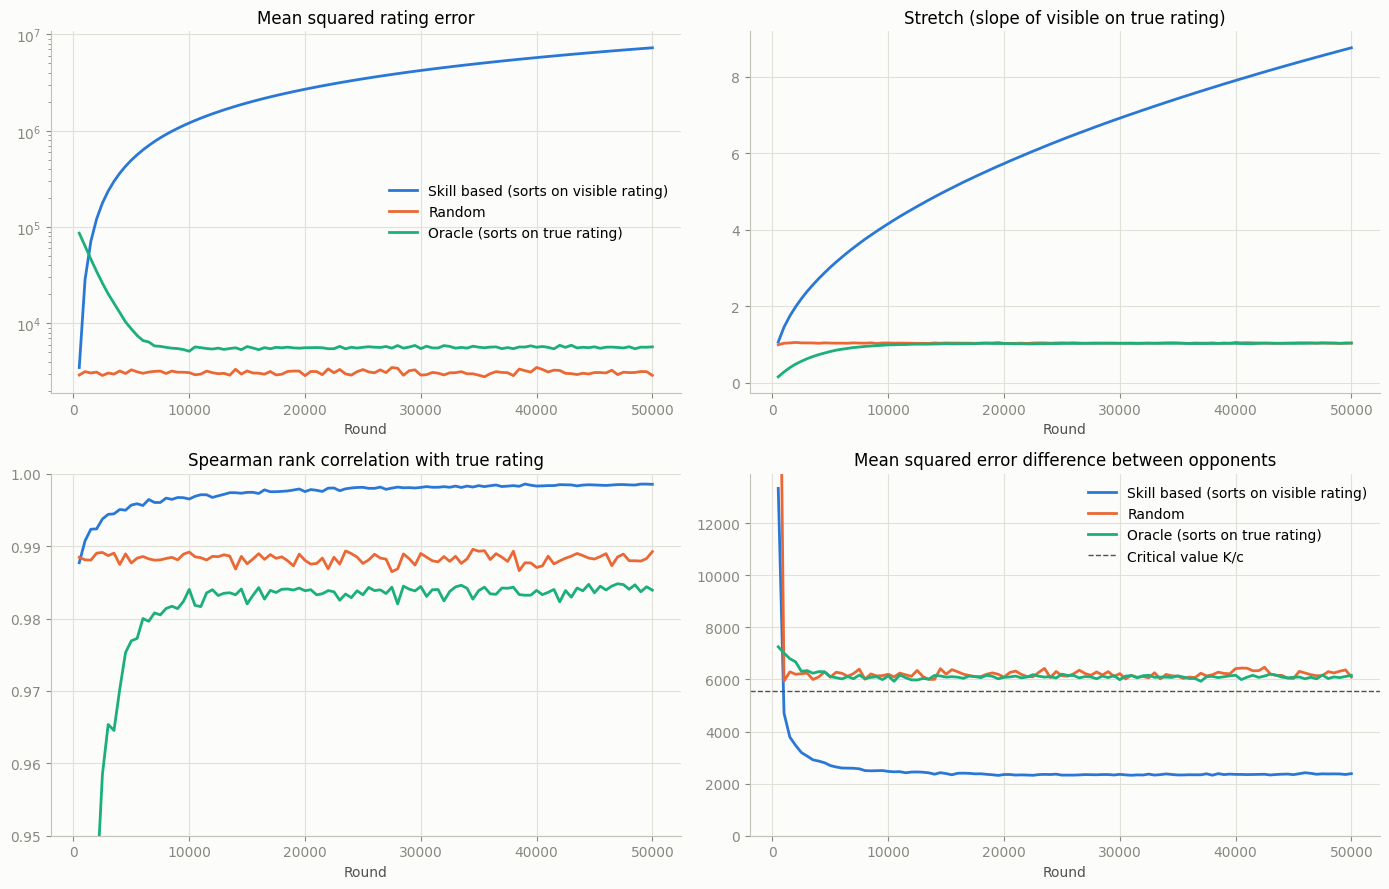

Matchmaking                                      MSE   Stretch  Spearman   E[de^2] opponents
Skill based (sorts on visible rating)        7276025      8.76    0.9986                2379
Random                                          2889      1.03    0.9892                6237
Oracle (sorts on true rating)                   5711      1.04    0.9839                6088
Critical value K/c = 5559


In [3]:
num_players, K, h, num_rounds = 1000, 32, 50, 50000
labels = ["Skill based (sorts on visible rating)", "Random", "Oracle (sorts on true rating)"]
colors = [BLUE, ORANGE, AQUA]

A = simulate(K, h, num_players, num_rounds, match_on=["rating", "rating", "true"], rho=[0, 1, 0],
             log_every=500, seed=1)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
panels = [("mse", "Mean squared rating error"),
          ("slope", "Stretch (slope of visible on true rating)"),
          ("spearman", "Spearman rank correlation with true rating"),
          ("matched_de2", "Mean squared error difference between opponents")]
for ax, (key, title) in zip(axs.ravel(), panels):
    for i in range(3):
        ax.plot(A["t"], A[key][:, i], color=colors[i], label=labels[i])
    ax.set_title(title)
    ax.set_xlabel("Round")
axs[0, 0].set_yscale("log")
axs[1, 0].set_ylim(0.95, 1.0)
axs[1, 1].axhline(critical_gap2(K), color=MUTED, linestyle="--", linewidth=1, label="Critical value K/c")
axs[1, 1].set_ylim(0, 2.5 * critical_gap2(K))
axs[0, 0].legend()
axs[1, 1].legend()
plt.tight_layout()
plt.show()

print(f"{'Matchmaking':<40}{'MSE':>12}{'Stretch':>10}{'Spearman':>10}{'E[de^2] opponents':>20}")
for i in range(3):
    print(f"{labels[i]:<40}{A['mse'][-1, i]:>12.0f}{A['slope'][-1, i]:>10.2f}{A['spearman'][-1, i]:>10.4f}"
          f"{A['matched_de2'][-10:, i].mean():>20.0f}")
print(f"Critical value K/c = {critical_gap2(K):.0f}")

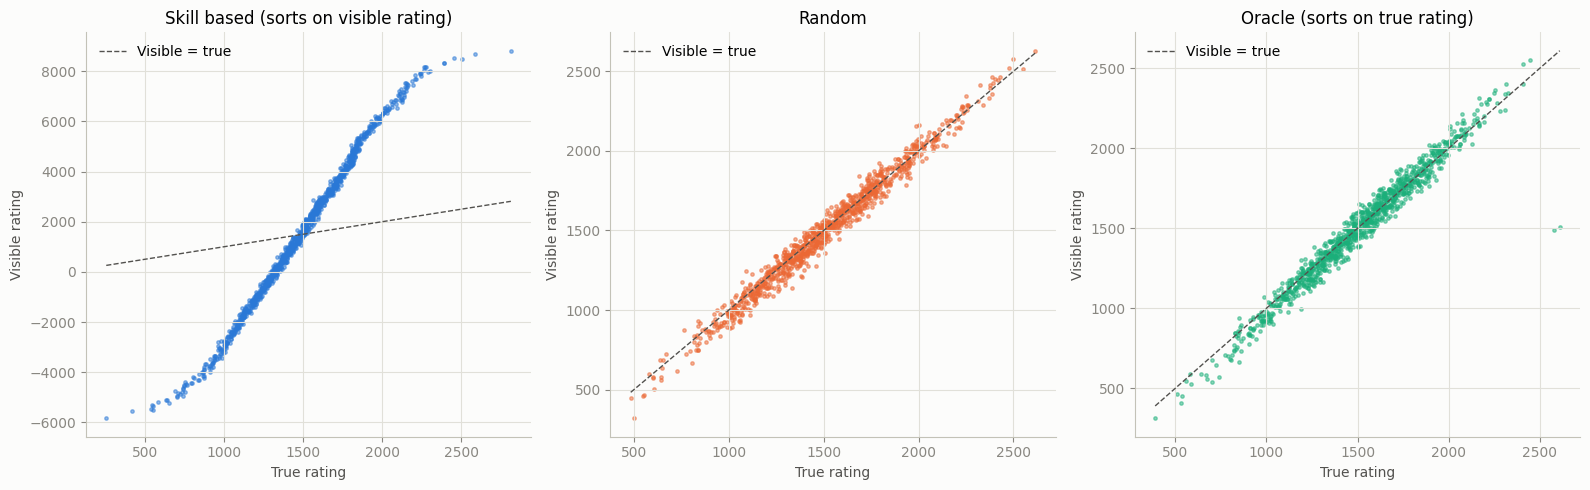

In [4]:
# Final visible vs. true ratings: skill based matchmaking keeps the order but stretches the scale
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, i in zip(axs, range(3)):
    ax.scatter(A["true_ratings"][i], A["ratings"][i], s=6, color=colors[i], alpha=0.5)
    lims = np.array([A["true_ratings"][i].min(), A["true_ratings"][i].max()])
    ax.plot(lims, lims, color=MUTED, linestyle="--", linewidth=1, label="Visible = true")
    ax.set_title(labels[i])
    ax.set_xlabel("True rating")
    ax.set_ylabel("Visible rating")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**B. The energy identity**

`simulate` accumulates the exact expected change of $\sum_i e_i^2$ in every round, split into noise injection $2K^2(p(1-p) + (p-q)^2)$ and dissipation $2K\Delta e(q - p)$. The realized change in MSE follows the identity. Under random and oracle matchmaking the two terms balance; under SBM injection wins.

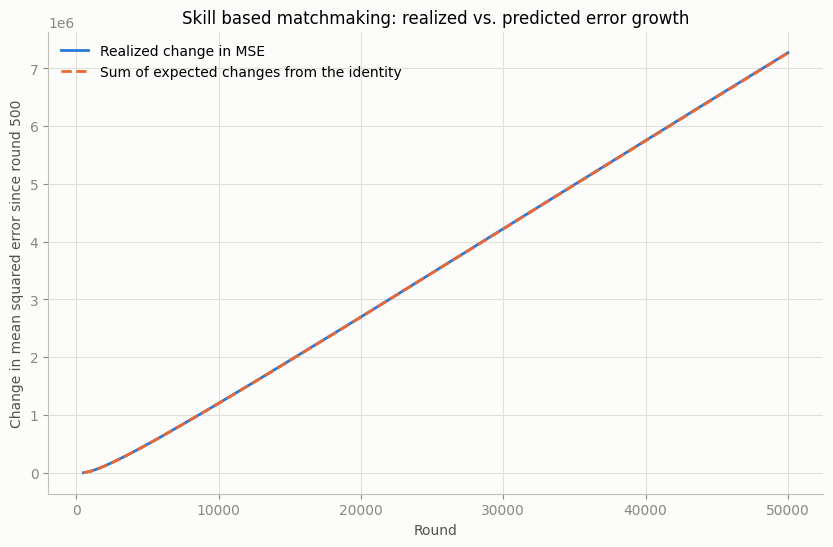

Per-round rates over the second half of the run (K = 32)
Matchmaking                               injection  dissipation  identity  realized
Skill based (sorts on visible rating)         258.9        106.5     152.4     152.5
Random                                        123.6        123.6      -0.1      -0.0
Oracle (sorts on true rating)                 263.9        264.1      -0.2      -0.0

Near-even approximation (K/4)(K - c E[de^2]) for skill based matchmaking: 147.6 per round


In [5]:
realized = A["mse"] - A["mse"][0]
predicted = (A["injection"] - A["dissipation"]) - (A["injection"][0] - A["dissipation"][0])

plt.figure(figsize=(10, 6))
plt.plot(A["t"], realized[:, 0], color=BLUE, label="Realized change in MSE")
plt.plot(A["t"], predicted[:, 0], color=ORANGE, linestyle="--", label="Sum of expected changes from the identity")
plt.title("Skill based matchmaking: realized vs. predicted error growth")
plt.xlabel("Round")
plt.ylabel("Change in mean squared error since round 500")
plt.legend()
plt.show()

half = len(A["t"]) // 2
span = A["t"][-1] - A["t"][half]
print(f"Per-round rates over the second half of the run (K = {K})")
print(f"{'Matchmaking':<40}{'injection':>11}{'dissipation':>13}{'identity':>10}{'realized':>10}")
for i in range(3):
    inj = (A["injection"][-1, i] - A["injection"][half, i]) / span
    dis = (A["dissipation"][-1, i] - A["dissipation"][half, i]) / span
    real = (A["mse"][-1, i] - A["mse"][half, i]) / span
    print(f"{labels[i]:<40}{inj:>11.1f}{dis:>13.1f}{inj - dis:>10.1f}{real:>10.1f}")
approx = K / 4 * (K - C * A["matched_de2"][half:, 0].mean())
print(f"\nNear-even approximation (K/4)(K - c E[de^2]) for skill based matchmaking: {approx:.1f} per round")

**C. When does it drift? Window width vs. rating constant**

Grid over $K \in \{8, 16, 32\}$ and matchmaking noise $h \in \{50, \dots, 300\}$. $W$ is the measured mean squared rating gap between opponents near the end of the run. The prediction is $s^* = W/(W - K/c)$ for $W > K/c$ and unbounded drift otherwise. Runs near the threshold equilibrate slowly, so some of them are still rising when the run ends.

In [6]:
Ks = np.array([8, 16, 32])
hs = np.array([50, 75, 100, 150, 200, 300])
KK, HH = np.meshgrid(Ks, hs, indexing="ij")
grid_K, grid_h = KK.ravel(), HH.ravel()
G = simulate(grid_K, grid_h, num_players=1000, num_rounds=60000, log_every=1000, seed=2)

late = slice(-12, None)  # last 20% of the run
W = G["matched_dr2"][late].mean(axis=0)
s_obs = G["slope"][-1]
s_pred = predicted_stretch(W, grid_K)
rising = (G["slope"][-1] - G["slope"][-12]) / G["slope"][-12] > 0.02

print(f"{'K':>4}{'h':>6}{'2h^2/3':>9}{'W':>9}{'K/c':>8}{'predicted s*':>14}{'observed s':>12}  status")
for j in range(len(grid_K)):
    pred = "inf" if np.isinf(s_pred[j]) else f"{s_pred[j]:.2f}"
    status = "still rising" if rising[j] else "settled"
    print(f"{grid_K[j]:>4}{grid_h[j]:>6}{2 * grid_h[j]**2 / 3:>9.0f}{W[j]:>9.0f}{critical_gap2(grid_K[j]):>8.0f}"
          f"{pred:>14}{s_obs[j]:>12.2f}  {status}")

   K     h   2h^2/3        W     K/c  predicted s*  observed s  status
   8    50     1667     1760    1390          4.76        2.12  still rising
   8    75     3750     3908    1390          1.55        1.58  settled
   8   100     6667     6783    1390          1.26        1.27  settled
   8   150    15000    14311    1390          1.11        1.11  settled
   8   200    26667    24469    1390          1.06        1.06  settled
   8   300    60000    48252    1390          1.03        1.03  settled
  16    50     1667     1914    2779           inf        4.32  still rising
  16    75     3750     3988    2779          3.30        2.94  still rising
  16   100     6667     6810    2779          1.69        1.78  settled
  16   150    15000    14500    2779          1.24        1.25  settled
  16   200    26667    24702    2779          1.13        1.13  settled
  16   300    60000    49397    2779          1.06        1.06  settled
  32    50     1667     2283    5559           inf

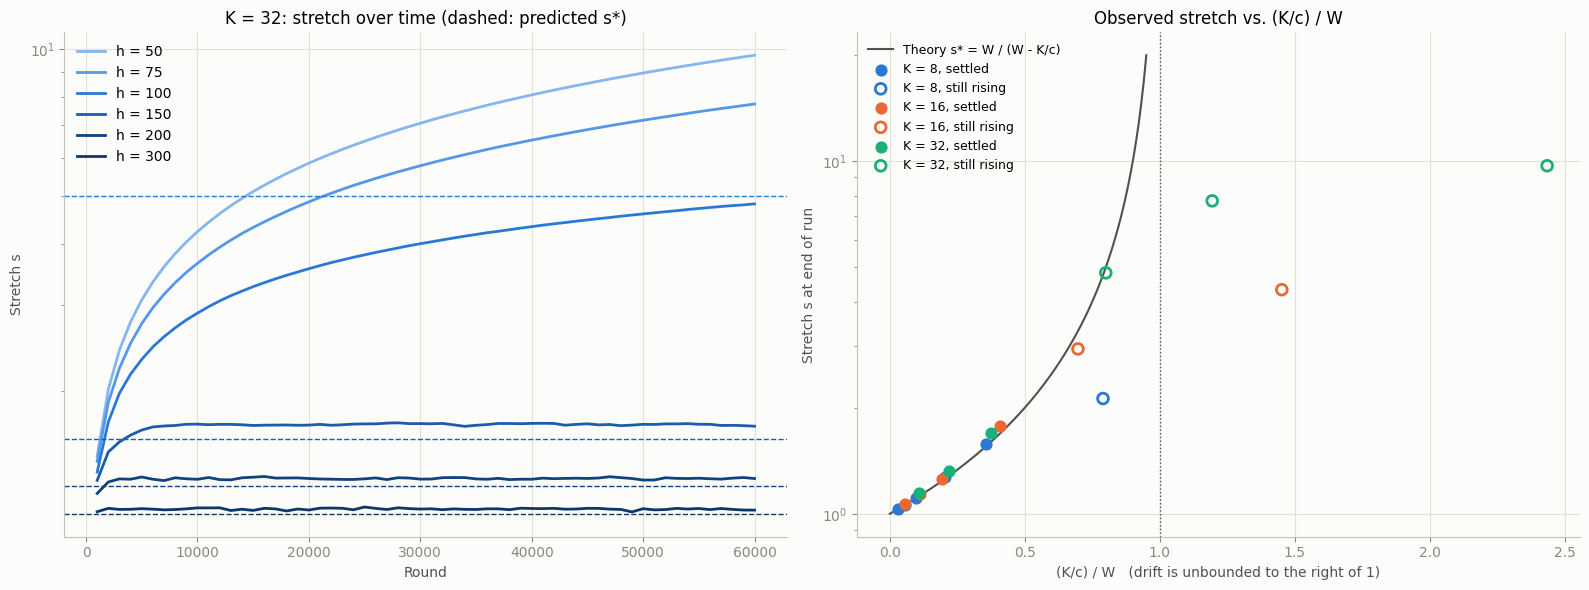

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Stretch over time for K = 32, with the predicted equilibrium as a dashed line of the same color
for j, color in zip(np.where(grid_K == 32)[0], RAMP):
    ax1.plot(G["t"], G["slope"][:, j], color=color, label=f"h = {grid_h[j]}")
    if np.isfinite(s_pred[j]):
        ax1.axhline(s_pred[j], color=color, linestyle="--", linewidth=1)
ax1.set_yscale("log")
ax1.set_title("K = 32: stretch over time (dashed: predicted s*)")
ax1.set_xlabel("Round")
ax1.set_ylabel("Stretch s")
ax1.legend()

# All runs against the theory curve s* = 1 / (1 - x), x = (K/c) / W
x = critical_gap2(grid_K) / W
xs = np.linspace(0, 0.95, 200)
ax2.plot(xs, 1 / (1 - xs), color=MUTED, linewidth=1.5, label="Theory s* = W / (W - K/c)")
ax2.axvline(1, color=MUTED, linestyle=":", linewidth=1)
for k, color in zip(Ks, [BLUE, ORANGE, AQUA]):
    sel = grid_K == k
    ax2.scatter(x[sel & ~rising], s_obs[sel & ~rising], s=60, color=color, label=f"K = {k}, settled", zorder=3)
    ax2.scatter(x[sel & rising], s_obs[sel & rising], s=60, facecolors="none", edgecolors=color, linewidths=2,
                label=f"K = {k}, still rising", zorder=3)
ax2.set_yscale("log")
ax2.set_title("Observed stretch vs. (K/c) / W")
ax2.set_xlabel("(K/c) / W   (drift is unbounded to the right of 1)")
ax2.set_ylabel("Stretch s at end of run")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

**D. Equal true ratings**

All 1000 players have true rating 1500, so every game is a fair coin flip. Under random matchmaking the error settles at $\mathrm{Var}(e) \approx K/(2c)$. Under SBM, $\Delta e = \Delta r$ for opponents, so $\mathbb{E}[\Delta e^2] = W$ is set only by the matchmaker and the ratings drift. Heterogeneous skill is not needed.

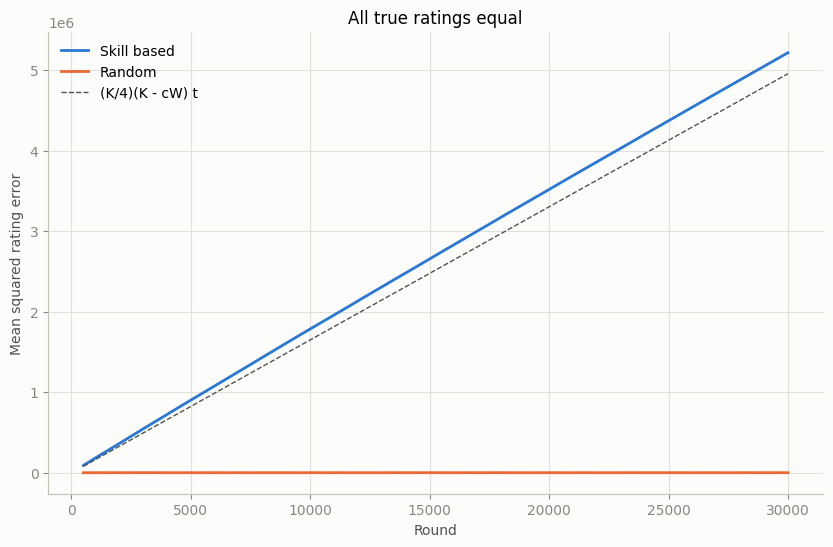

Skill based: MSE = 5216109, W = 1972 < K/c = 5559
Random:      MSE = 2919  (K/2c = 2779)


In [8]:
equal = np.full(1000, 1500.0)
D = simulate(32, 50, 1000, 30000, true_ratings=equal, rho=[0, 1], log_every=500, seed=3)

plt.figure(figsize=(10, 6))
plt.plot(D["t"], D["mse"][:, 0], color=BLUE, label="Skill based")
plt.plot(D["t"], D["mse"][:, 1], color=ORANGE, label="Random")
W_eq = D["matched_dr2"][len(D["t"]) // 2:, 0].mean()
plt.plot(D["t"], 32 / 4 * (32 - C * W_eq) * D["t"], color=MUTED, linestyle="--", linewidth=1,
         label="(K/4)(K - cW) t")
plt.title("All true ratings equal")
plt.xlabel("Round")
plt.ylabel("Mean squared rating error")
plt.legend()
plt.show()

print(f"Skill based: MSE = {D['mse'][-1, 0]:.0f}, W = {W_eq:.0f} < K/c = {critical_gap2(32):.0f}")
print(f"Random:      MSE = {D['mse'][-1, 1]:.0f}  (K/2c = {critical_gap2(32) / 2:.0f})")

**E. A finite player pool saturates**

With few players, the gaps between neighbours on the ladder grow as the ratings spread, which raises $W$. The spread stops growing once $W$ reaches $K/c$, so the drift is bounded for finite $N$ and the bound grows with $N$.

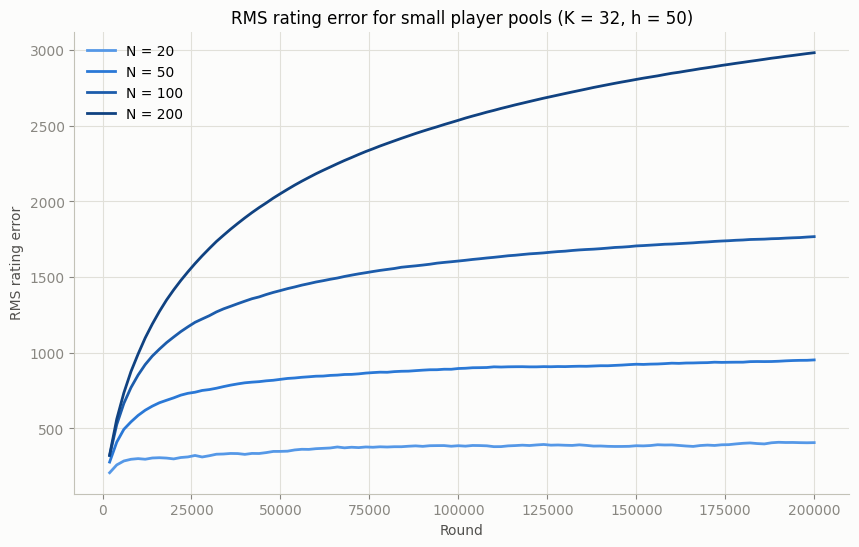

    N  RMS @50k  RMS @100k  RMS @200k    range  range/N  E[de^2] opp.
   20       349        386        407     2155      108          6026
   50       825        896        953     4942       99          6077
  100      1411       1606       1767     7590       76          5970
  200      2051       2536       2982    12553       63          5592
K/c = 5559


In [9]:
pool_sizes = [20, 50, 100, 200]
E = {N: simulate(32, 50, N, 200000, log_every=2000, seed=N) for N in pool_sizes}

plt.figure(figsize=(10, 6))
for N, color in zip(pool_sizes, RAMP[1:]):
    plt.plot(E[N]["t"], np.sqrt(E[N]["mse"][:, 0]), color=color, label=f"N = {N}")
plt.title("RMS rating error for small player pools (K = 32, h = 50)")
plt.xlabel("Round")
plt.ylabel("RMS rating error")
plt.legend()
plt.show()

print(f"{'N':>5}{'RMS @50k':>10}{'RMS @100k':>11}{'RMS @200k':>11}{'range':>9}{'range/N':>9}{'E[de^2] opp.':>14}")
for N in pool_sizes:
    rms, r = np.sqrt(E[N]["mse"][:, 0]), E[N]["ratings"][0]
    print(f"{N:>5}{rms[24]:>10.0f}{rms[49]:>11.0f}{rms[-1]:>11.0f}{np.ptp(r):>9.0f}{np.ptp(r) / N:>9.0f}"
          f"{E[N]['matched_de2'][-10:, 0].mean():>14.0f}")
print(f"K/c = {critical_gap2(32):.0f}")

**F. Bounded ratings become percentiles**

Same as `match_all_realistic(bounded=True)`: ratings are clipped to $[0, 3000]$ after every round. The histogram is uniform as in `rating_drift_analysis.ipynb`, but the players have not lost their order. The visible rating is close to $3000 \times$ the player's true percentile.

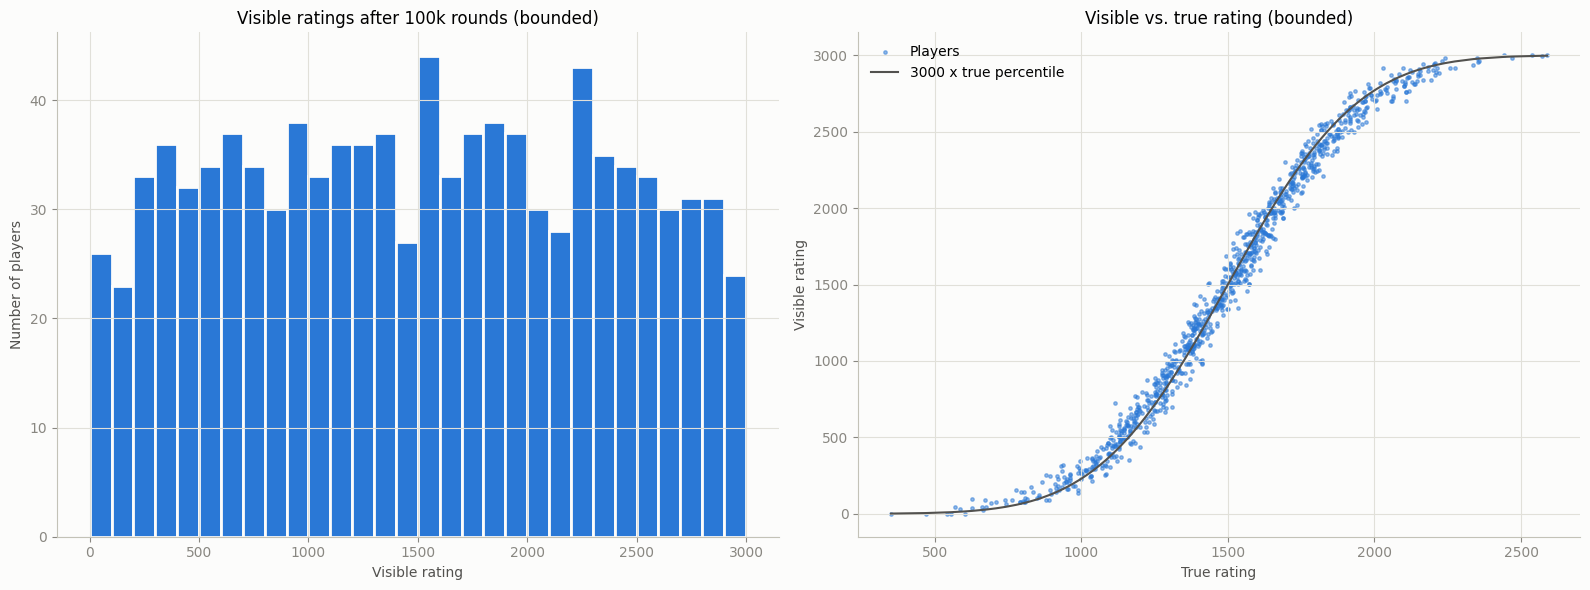

Spearman(visible, true) = 0.9951
RMS distance to 3000 x true percentile = 91.0


In [10]:
F = simulate(32, 50, 1000, 100000, bounded=(0, 3000), log_every=10000, seed=5)
r_b, th_b = F["ratings"][0], F["true_ratings"][0]
percentile_curve = 3000 * norm.cdf((th_b - 1500) / 350)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.hist(r_b, bins=30, range=(0, 3000), color=BLUE, edgecolor="#fcfcfb", linewidth=2)
ax1.set_title("Visible ratings after 100k rounds (bounded)")
ax1.set_xlabel("Visible rating")
ax1.set_ylabel("Number of players")
order = np.argsort(th_b)
ax2.scatter(th_b, r_b, s=6, color=BLUE, alpha=0.5, label="Players")
ax2.plot(th_b[order], percentile_curve[order], color=MUTED, linewidth=1.5, label="3000 x true percentile")
ax2.set_title("Visible vs. true rating (bounded)")
ax2.set_xlabel("True rating")
ax2.set_ylabel("Visible rating")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Spearman(visible, true) = {spearman(r_b, th_b):.4f}")
print(f"RMS distance to 3000 x true percentile = {np.sqrt(np.mean((r_b - percentile_curve) ** 2)):.1f}")

**G. What the regret metric can and cannot see**

The regret in `rating_drift_analysis.ipynb` is the excess log loss on the games that were actually played. Under SBM those are the pairs on which the drift is invisible. Evaluating the same final ratings on uniformly random pairs shows the difference.

Matchmaking                               matched pairs  random pairs
Skill based (sorts on visible rating)            0.0098        1.1806
Random                                           0.0219        0.0106
Oracle (sorts on true rating)                    0.0201        0.0160
(expected excess log loss in nats per game, after 50000 rounds)


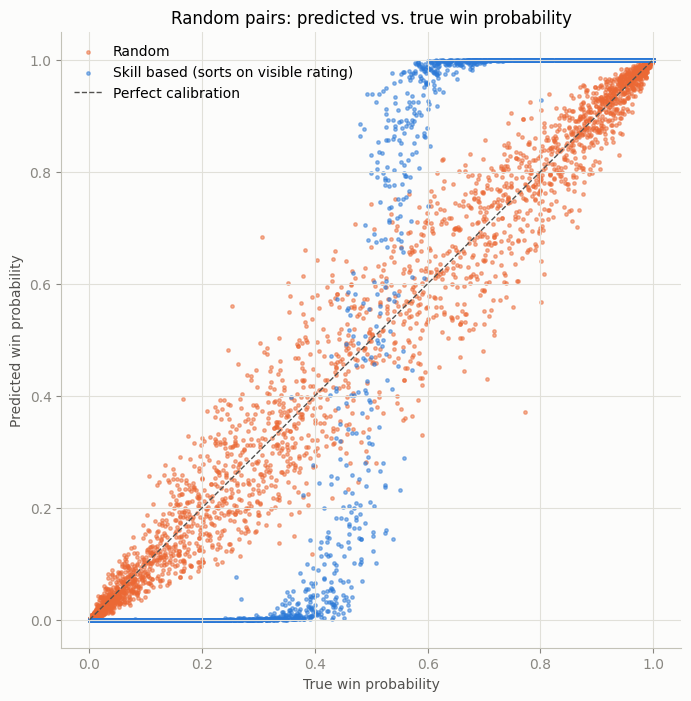

In [11]:
rng = np.random.RandomState(6)
print(f"{'Matchmaking':<40}{'matched pairs':>15}{'random pairs':>14}")
for i in range(3):
    r, th = A["ratings"][i], A["true_ratings"][i]
    m1, m2 = matched_pairs(r, 50, rng)
    q1, q2 = random_pairs(len(r), rng=rng)
    print(f"{labels[i]:<40}{excess_log_loss(r, th, m1, m2):>15.4f}{excess_log_loss(r, th, q1, q2):>14.4f}")
print("(expected excess log loss in nats per game, after", num_rounds, "rounds)")

# Calibration on random pairs: predicted vs. true win probability
from func import prob_log
q1, q2 = random_pairs(num_players, 3000, rng=rng)
plt.figure(figsize=(8, 8))
for i in [1, 0]:
    r, th = A["ratings"][i], A["true_ratings"][i]
    plt.scatter(prob_log(th[q1], th[q2]), prob_log(r[q1], r[q2]), s=6, alpha=0.5, color=colors[i], label=labels[i])
plt.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Perfect calibration")
plt.title("Random pairs: predicted vs. true win probability")
plt.xlabel("True win probability")
plt.ylabel("Predicted win probability")
plt.legend(loc="upper left")
plt.show()

**H. Decaying $K$ and random exploration rounds**

Decaying $K$ pushes $K/c$ below $W$ and stops the drift, but under SBM there is no force that undoes stretch that already exists. Mixing in a fraction $\rho$ of random-matchmaking rounds adds games between distant players. That bounds the drift, but very uneven games saturate the logistic, so the bound is loose unless $\rho$ is large.

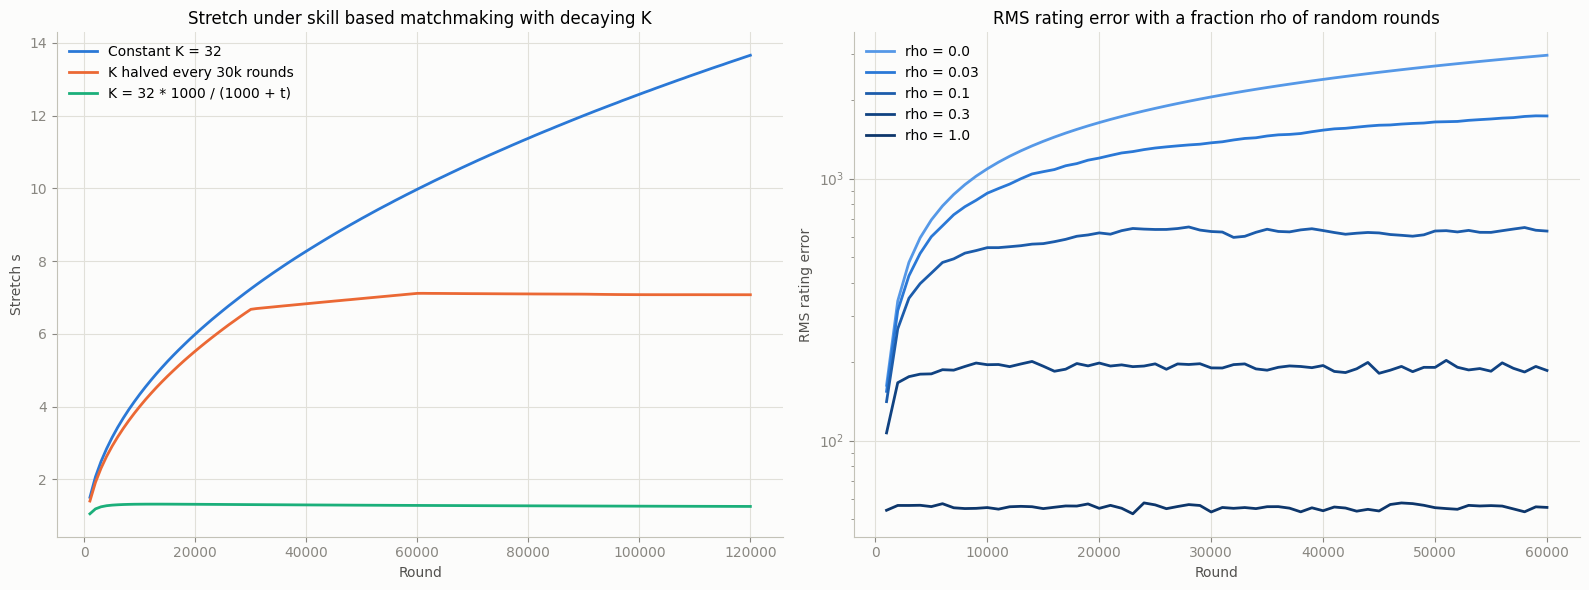

Constant K = 32                stretch @30k = 7.24   @120k = 13.66   RMS @120k = 4199
K halved every 30k rounds      stretch @30k = 6.68   @120k = 7.08   RMS @120k = 2190
K = 32 * 1000 / (1000 + t)     stretch @30k = 1.31   @120k = 1.26   RMS @120k = 92

rho = 0.0   RMS error @30k =   2050   @60k =   2956
rho = 0.03  RMS error @30k =   1369   @60k =   1734
rho = 0.1   RMS error @30k =    628   @60k =    631
rho = 0.3   RMS error @30k =    189   @60k =    185
rho = 1.0   RMS error @30k =     53   @60k =     56


In [12]:
schedules = ["Constant K = 32", "K halved every 30k rounds", "K = 32 * 1000 / (1000 + t)"]
H1 = simulate([32, 32, 32], 50, 1000, 120000, log_every=1000, seed=7,
              k_schedule=lambda t: [1.0, 0.5 ** ((t - 1) // 30000), 1000 / (1000 + t)])

rhos = [0.0, 0.03, 0.1, 0.3, 1.0]
H2 = simulate(32, 50, 1000, 60000, rho=rhos, log_every=1000, seed=8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for i, color in enumerate([BLUE, ORANGE, AQUA]):
    ax1.plot(H1["t"], H1["slope"][:, i], color=color, label=schedules[i])
ax1.set_title("Stretch under skill based matchmaking with decaying K")
ax1.set_xlabel("Round")
ax1.set_ylabel("Stretch s")
ax1.legend()
for i, color in enumerate(RAMP[1:]):
    ax2.plot(H2["t"], np.sqrt(H2["mse"][:, i]), color=color, label=f"rho = {rhos[i]}")
ax2.set_yscale("log")
ax2.set_title("RMS rating error with a fraction rho of random rounds")
ax2.set_xlabel("Round")
ax2.set_ylabel("RMS rating error")
ax2.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(schedules):
    print(f"{name:<30} stretch @30k = {H1['slope'][29, i]:.2f}   @120k = {H1['slope'][-1, i]:.2f}   "
          f"RMS @120k = {np.sqrt(H1['mse'][-1, i]):.0f}")
print()
for i, rho in enumerate(rhos):
    print(f"rho = {rho:<5} RMS error @30k = {np.sqrt(H2['mse'][29, i]):>6.0f}   @60k = {np.sqrt(H2['mse'][-1, i]):>6.0f}")

**I. Glicko and Glicko2**

The Glicko update is $\Delta r = q\,RD'^2 g\,(s - E)$ with $q = c$, so its effective $K$ is $c\,RD'^2 g$ and the critical gap $K/c$ (with the logistic slope $cg$) is just $RD'^2$. The drift condition becomes $W < RD'^2$. Both classes below are used unchanged, with their own `match_all_realistic` ($N(0, 30)$ key noise, so $W \approx 2 \cdot 30^2 = 1800$).

Glicko:  RD'^2 = 893, W = 1800  ->  predicted s* = 1.99, observed s = 1.69 after 100000 rounds


Glicko2: mean RD^2 = 3656 > W = 1800  ->  unbounded drift predicted, observed s = 2.19 after 6000 rounds


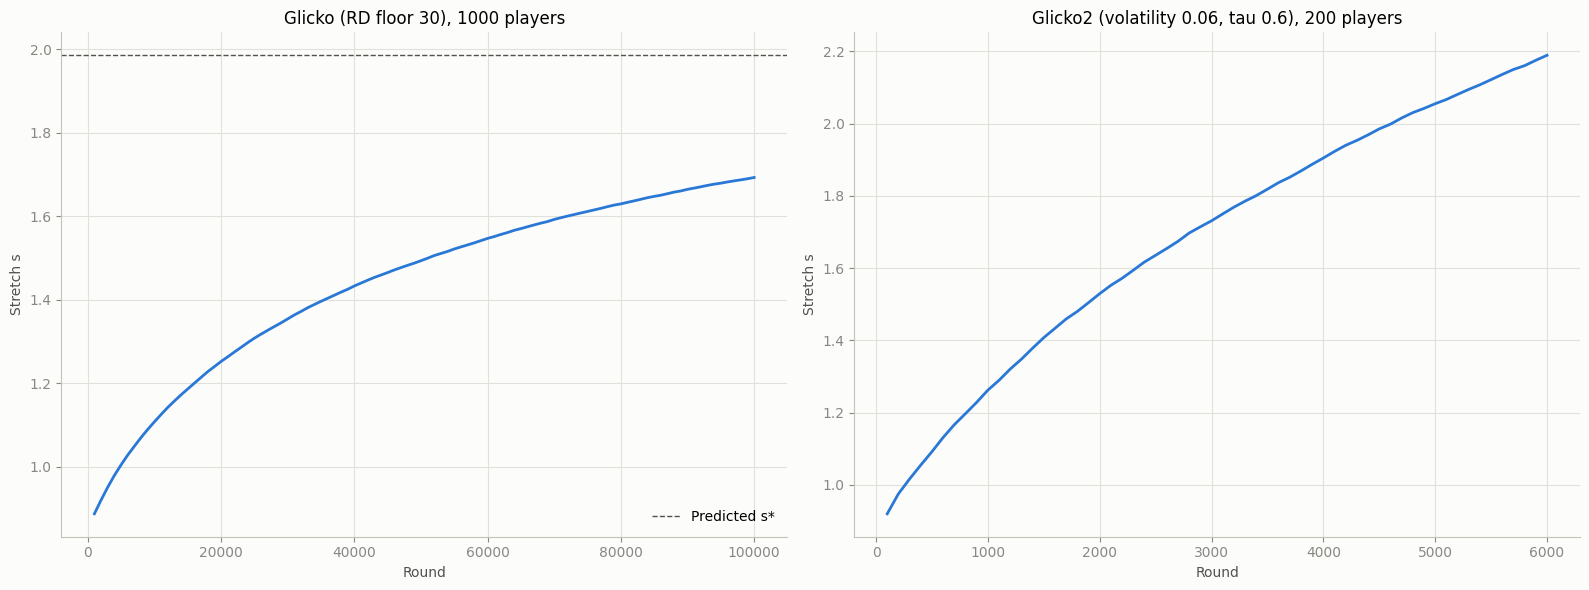

In [13]:
from glicko import Glicko
from glicko2 import Glicko2

np.random.seed(9)
n = 1000
th_g = np.random.normal(1500, 350, n).astype(np.float32)
glicko = Glicko(n, np.full(n, 1500, dtype=np.float32), th_g, np.full(n, 350, dtype=np.float32))
glicko_t, glicko_s = [], []
for t in range(1, 100001):
    glicko.match_all_realistic(1)
    if t % 1000 == 0:
        glicko_t.append(t)
        glicko_s.append(stretch(glicko.ratings.astype(float), th_g.astype(float)))

# RD after one game, before the floor of 30 is applied
g = 1 / np.sqrt(1 + 3 * C**2 * 30**2 / np.pi**2)
rd2 = 1 / (1 / 30**2 + C**2 * g**2 / 4)
print(f"Glicko:  RD'^2 = {rd2:.0f}, W = 1800  ->  predicted s* = {1800 / (1800 - rd2):.2f}, "
      f"observed s = {glicko_s[-1]:.2f} after {glicko_t[-1]} rounds")

np.random.seed(10)
n2 = 200
th_g2 = np.random.normal(1500, 350, n2).astype(np.float32)
glicko2 = Glicko2(n2, np.full(n2, 1500, dtype=np.float32), th_g2, np.full(n2, 350, dtype=np.float32),
                  np.full(n2, 0.06, dtype=np.float32), 0.6)
glicko2_t, glicko2_s = [], []
for t in range(1, 6001):
    glicko2.match_all_realistic(1)
    if t % 100 == 0:
        glicko2_t.append(t)
        glicko2_s.append(stretch(glicko2.ratings.astype(float), th_g2.astype(float)))
rd2_g2 = np.mean(glicko2.rating_devs.astype(float) ** 2)
print(f"Glicko2: mean RD^2 = {rd2_g2:.0f} > W = 1800  ->  unbounded drift predicted, "
      f"observed s = {glicko2_s[-1]:.2f} after {glicko2_t[-1]} rounds")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.plot(glicko_t, glicko_s, color=BLUE)
ax1.axhline(1800 / (1800 - rd2), color=MUTED, linestyle="--", linewidth=1, label="Predicted s*")
ax1.set_title("Glicko (RD floor 30), 1000 players")
ax1.set_xlabel("Round")
ax1.set_ylabel("Stretch s")
ax1.legend()
ax2.plot(glicko2_t, glicko2_s, color=BLUE)
ax2.set_title("Glicko2 (volatility 0.06, tau 0.6), 200 players")
ax2.set_xlabel("Round")
ax2.set_ylabel("Stretch s")
plt.tight_layout()
plt.show()

**J. The bounded case: a heat equation for the rating density**

Once the scale has drifted, games between opponents are coin flips and the dynamics no longer depend on true skill. Here is what happens to the *density* $n(r, t)$ of visible ratings in that regime (heuristic, many players):

* A player at rating $r$ is sorted on $r + \eta$, where $\eta$ is the matchmaking noise with $\mathrm{Var}(\eta) = W/2$. The opponent has the adjacent key, so the opponent's rating is drawn from the players inside the noise window around that key, weighted by the density: $\mathbb{E}[r_j - r] \approx \frac{n'(r)}{n(r)}\,\mathrm{Var}(\eta) = \frac{n'}{n}\cdot\frac{W}{2}$.
* In a coin flip the expected Elo change is $K\left(\tfrac12 - \sigma(r - r_j)\right) \approx \frac{Kc}{4}(r_j - r)$: opponents are pulled together. So the mean drift is $v(r) = \frac{KcW}{8}\cdot\frac{n'}{n}$, towards higher density.
* Each game moves the player by $\pm K/2$, which is a diffusion with coefficient $K^2/8$ per round.

The Fokker-Planck equation is then

$$\partial_t n = \partial_r\left(\frac{K^2}{8}\,\partial_r n - v\,n\right) = D\,\partial_r^2 n, \qquad D = \frac{K}{8}\left(K - cW\right).$$

Clipping keeps players at the walls, so the walls have zero flux, and the solution is

$$n(r, t) = \frac{1}{L} + \sum_{k \ge 1} a_k\, e^{-D (k\pi/L)^2 t} \cos\frac{k\pi r}{L} \;\longrightarrow\; \frac{1}{L}.$$

Each cosine mode decays at rate $D(k\pi/L)^2$, and the slowest one sets the relaxation time $L^2/(\pi^2 D)$.

**Fluctuations around the percentile.** A player who sits $u$ rating points above the ladder's line is matched with players whose true skill is about $u/s$ higher, where $s$ is the local stretch. Such a player is expected to lose $\frac{Kc}{4}\cdot\frac{u}{s}$ per game while receiving $\pm K/2$ of noise, so the stationary variance is $V = s\,K/(2c)$. In the bounded state $s(\theta) = L\,f(\theta)$, so the SD is largest in the dense middle of the skill distribution. In true-skill units the misplacement is $\sqrt{K/(2cs)}$, so ranking is most precise where players are densest.

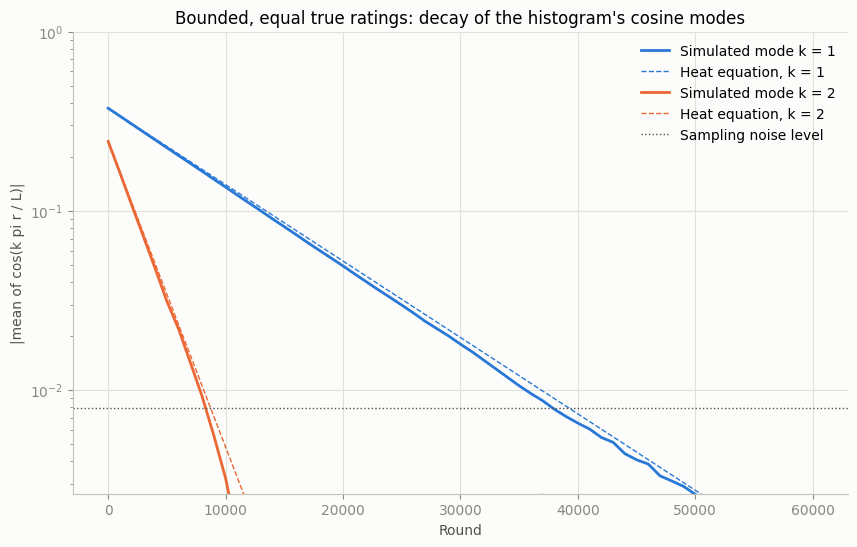

Predicted D = (K/8)(K - cW) = 89.6  (W = 1669)
Mode k = 1: fitted decay rate 1.01e-04  ->  D = 92.5
Mode k = 2: fitted decay rate 4.09e-04  ->  D = 93.2
Relaxation time L^2 / (pi^2 D) = 10180 rounds


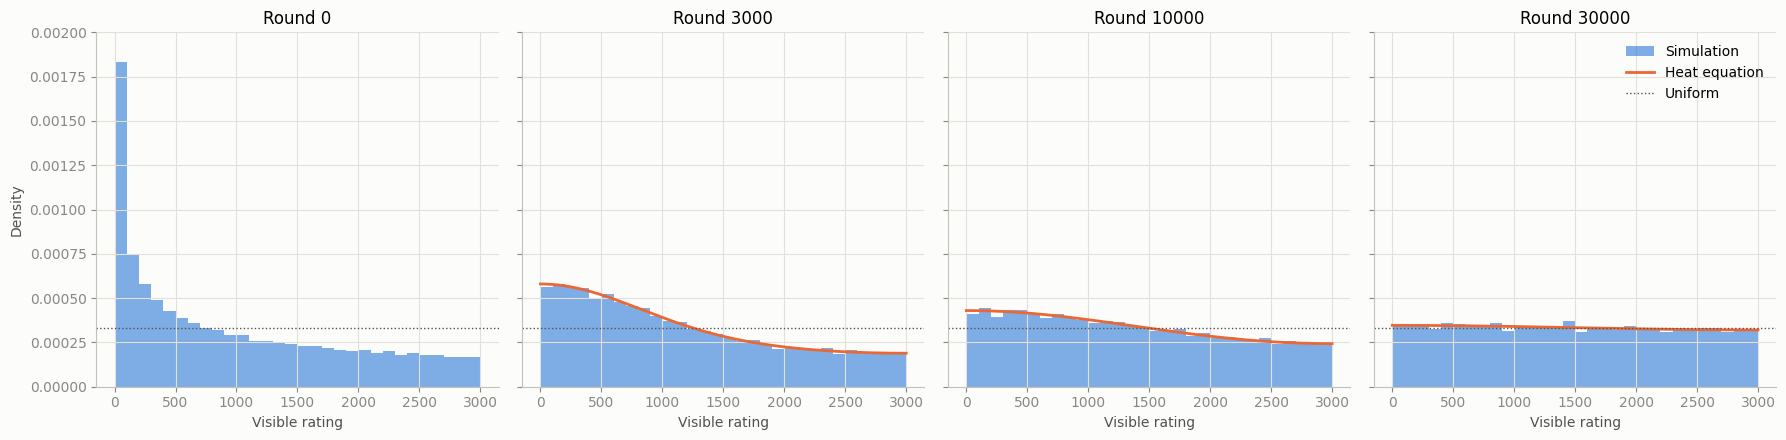

Unbounded kurtosis (normal = 3): equal true ratings (Section D) 2.53, normal true ratings (Section A) 2.49


In [14]:
# Heat equation test: equal true ratings, start from an ordered but skewed profile (crowded near 0)
L, n_rep = 3000.0, 8
rng = np.random.default_rng(40)
u = np.array([rng.permutation(1000) for _ in range(n_rep)])
start = L * ((u + 0.5) / 1000) ** 2
J1 = simulate([32] * n_rep, 50, 1000, 60000, true_ratings=np.full(1000, 1500.0), init_ratings=start,
              bounded=(0, L), keep_ratings=True, log_every=1000, seed=41)
J1_hist = np.concatenate([start[None], np.array(J1["history"])])   # (logs + 1, replicates, players)
J1_t = np.concatenate([[0], J1["t"]])
D_J1 = effective_diffusion(32, J1["matched_dr2"].mean())
modes = np.array([cosine_modes(H, L, [1, 2]) for H in J1_hist])
noise = 1 / np.sqrt(2 * 1000 * n_rep)   # standard error of a mode amplitude for a uniform sample

fig, ax = plt.subplots(figsize=(10, 6))
for k, color in zip([1, 2], [BLUE, ORANGE]):
    ax.plot(J1_t, np.abs(modes[:, k - 1]), color=color, label=f"Simulated mode k = {k}")
    ax.plot(J1_t, np.abs(modes[0, k - 1]) * np.exp(-D_J1 * (k * np.pi / L) ** 2 * J1_t), color=color,
            linestyle="--", linewidth=1, label=f"Heat equation, k = {k}")
ax.axhline(noise, color=MUTED, linestyle=":", linewidth=1, label="Sampling noise level")
ax.set_yscale("log")
ax.set_ylim(noise / 3, 1)
ax.set_title("Bounded, equal true ratings: decay of the histogram's cosine modes")
ax.set_xlabel("Round")
ax.set_ylabel("|mean of cos(k pi r / L)|")
ax.legend()
plt.show()

print(f"Predicted D = (K/8)(K - cW) = {D_J1:.1f}  (W = {J1['matched_dr2'].mean():.0f})")
for k in [1, 2]:
    a = np.abs(modes[:, k - 1])
    n_fit = np.argmax(a < 4 * noise) if np.any(a < 4 * noise) else len(a)
    rate = -np.polyfit(J1_t[:n_fit], np.log(a[:n_fit]), 1)[0]
    print(f"Mode k = {k}: fitted decay rate {rate:.2e}  ->  D = {rate / (k * np.pi / L) ** 2:.1f}")
print(f"Relaxation time L^2 / (pi^2 D) = {L**2 / (np.pi**2 * D_J1):.0f} rounds")

x = np.linspace(0, L, 301)
edges = np.linspace(0, L, 31)
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, tt in zip(axs, [0, 3000, 10000, 30000]):
    i = np.searchsorted(J1_t, tt)
    ax.hist(J1_hist[i].ravel(), bins=edges, density=True, color=BLUE, alpha=0.6, label="Simulation")
    if tt > 0:
        ax.plot(x, heat_density(start, D_J1, tt, x, L), color=ORANGE, label="Heat equation")
    ax.axhline(1 / L, color=MUTED, linestyle=":", linewidth=1, label="Uniform")
    ax.set_title(f"Round {tt}")
    ax.set_xlabel("Visible rating")
axs[0].set_ylabel("Density")
axs[0].set_ylim(0, 6 / L)
axs[-1].legend()
plt.tight_layout()
plt.show()

# Free space: the same equation gives the "flattening normal"; with 1000 players the sparse tails
# have larger neighbour gaps (larger W, smaller D), so the shape is slightly flatter than normal
print(f"Unbounded kurtosis (normal = 3): equal true ratings (Section D) {kurtosis(D['ratings'][0], fisher=False):.2f}, "
      f"normal true ratings (Section A) {kurtosis(A['ratings'][0], fisher=False):.2f}")

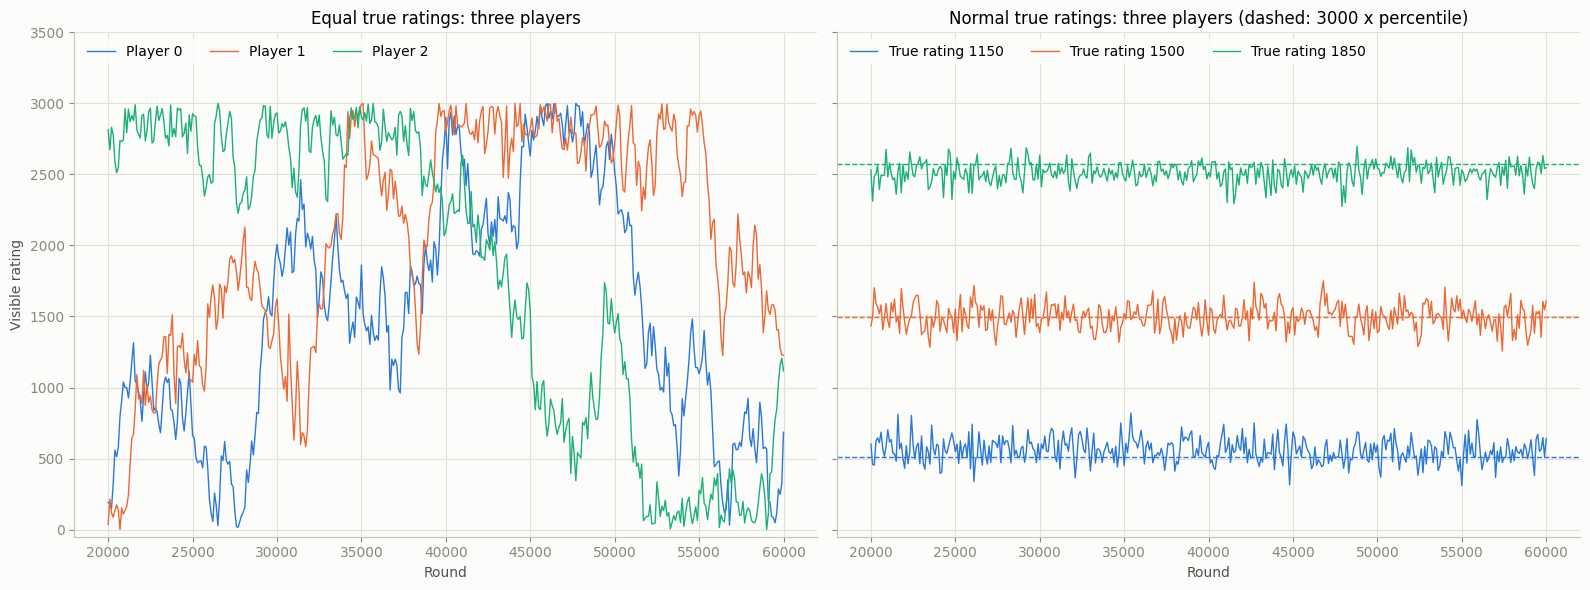

Equal true ratings : SD of a player's rating over time =  720 (uniform on [0, L]: 866),  KS distance of the histogram to uniform = 0.009
Normal true ratings: SD of a player's rating over time =   80 (uniform on [0, L]: 866),  KS distance of the histogram to uniform = 0.024


In [15]:
# Individual players: with equal true ratings each player roams the whole box (the Markov chain picture);
# with heterogeneous true ratings each player stays near their percentile, yet the histogram is uniform in both
th_J2 = np.vstack([np.full(1000, 1500.0), np.random.default_rng(42).normal(1500, 350, 1000)])
J2 = simulate([32, 32], 50, 1000, 60000, true_ratings=th_J2, bounded=(0, L), keep_ratings=True,
              log_every=100, seed=43)
J2_hist = np.array(J2["history"])
late = J2["t"] >= 20000
pct_J2 = (np.argsort(np.argsort(th_J2[1])) + 0.5) / 1000 * L
z_J2 = (th_J2[1] - 1500) / 350
picks = [np.argmin(np.abs(z_J2 - zz)) for zz in (-1, 0, 1)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for p, color in zip([0, 1, 2], [BLUE, ORANGE, AQUA]):
    ax1.plot(J2["t"][late], J2_hist[late, 0, p], color=color, linewidth=1, label=f"Player {p}")
for p, color in zip(picks, [BLUE, ORANGE, AQUA]):
    ax2.plot(J2["t"][late], J2_hist[late, 1, p], color=color, linewidth=1, label=f"True rating {th_J2[1, p]:.0f}")
    ax2.axhline(pct_J2[p], color=color, linestyle="--", linewidth=1)
ax1.set_title("Equal true ratings: three players")
ax2.set_title("Normal true ratings: three players (dashed: 3000 x percentile)")
for ax in (ax1, ax2):
    ax.set_xlabel("Round")
    ax.legend(loc="upper left", ncol=3, frameon=True, facecolor="#fcfcfb", edgecolor="none", framealpha=0.9)
ax1.set_ylabel("Visible rating")
ax1.set_ylim(-50, L + 500)
plt.tight_layout()
plt.show()

for j, name in enumerate(["Equal true ratings ", "Normal true ratings"]):
    traj = J2_hist[late, j]
    print(f"{name}: SD of a player's rating over time = {traj.std(axis=0).mean():4.0f} "
          f"(uniform on [0, L]: {L / np.sqrt(12):.0f}),  KS distance of the histogram to uniform = "
          f"{kstest(J2['ratings'][j] / L, 'uniform').statistic:.3f}")

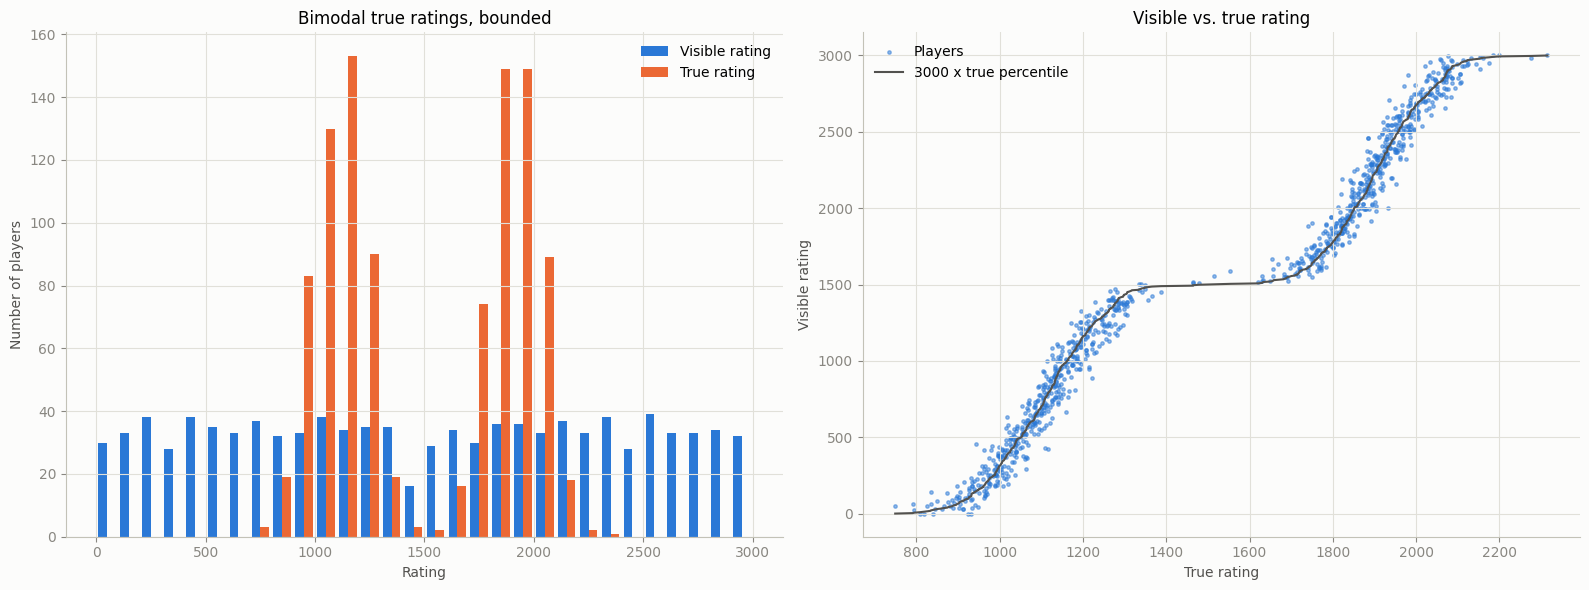

KS distance to uniform = 0.016, Spearman = 0.9933, RMS distance to 3000 x percentile = 100


In [16]:
# Any skill distribution gives the same uniform histogram: ratings become 3000 x true percentile
rng = np.random.default_rng(44)
th_bi = np.concatenate([rng.normal(1100, 120, 500), rng.normal(1900, 120, 500)])
J3 = simulate(32, 50, 1000, 60000, true_ratings=th_bi, bounded=(0, L), log_every=10000, seed=45)
r_bi = J3["ratings"][0]
pct_bi = (np.argsort(np.argsort(th_bi)) + 0.5) / 1000 * L

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.hist([r_bi, th_bi], bins=30, range=(0, L), color=[BLUE, ORANGE], label=["Visible rating", "True rating"])
ax1.set_title("Bimodal true ratings, bounded")
ax1.set_xlabel("Rating")
ax1.set_ylabel("Number of players")
ax1.legend()
order = np.argsort(th_bi)
ax2.scatter(th_bi, r_bi, s=6, color=BLUE, alpha=0.5, label="Players")
ax2.plot(th_bi[order], pct_bi[order], color=MUTED, linewidth=1.5, label="3000 x true percentile")
ax2.set_title("Visible vs. true rating")
ax2.set_xlabel("True rating")
ax2.set_ylabel("Visible rating")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"KS distance to uniform = {kstest(r_bi / L, 'uniform').statistic:.3f}, Spearman = {spearman(r_bi, th_bi):.4f}, "
      f"RMS distance to 3000 x percentile = {np.sqrt(np.mean((r_bi - pct_bi) ** 2)):.0f}")

z bin            K=32 sim   pred   K=64 sim   pred
[-3.0, -2.0)         33     29         45     40
[-2.0, -1.5)         50     47         67     66
[-1.5, -1.0)         66     67         96     95
[-1.0, -0.5)         86     84        121    119
[-0.5, +0.0)         98     96        140    135
[+0.0, +0.5)         95     96        138    135
[+0.5, +1.0)         82     84        121    119
[+1.0, +1.5)         68     67        100     95
[+1.5, +2.0)         50     47         69     67
[+2.0, +3.0)         34     26         40     37


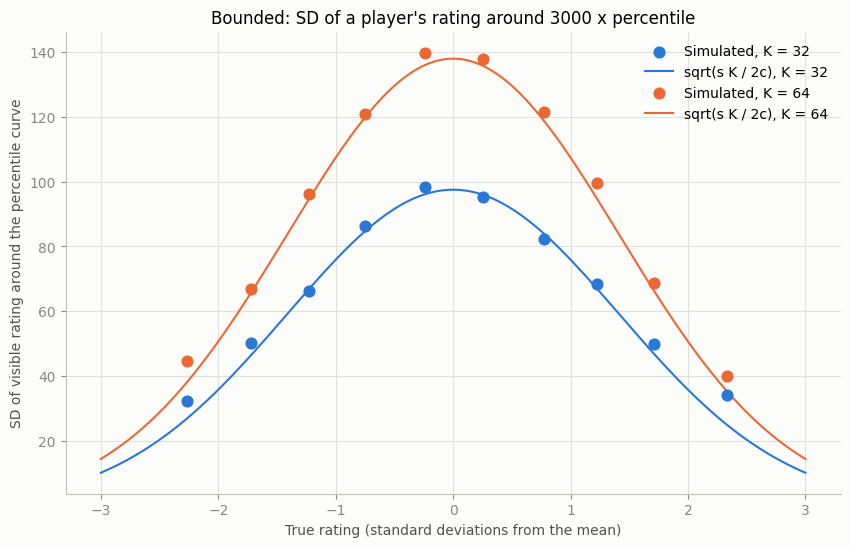

In [17]:
# Fluctuations around the percentile: SD by true-rating bin vs. sqrt(s K / 2c), s = L f(theta)
th_J4 = np.random.default_rng(46).normal(1500, 350, 1000)
J4 = simulate([32, 64], 50, 1000, 100000, true_ratings=th_J4, bounded=(0, L), keep_ratings=True,
              log_every=2500, seed=47)
snapshots = np.array(J4["history"])[20:]   # last 50k rounds
pct_J4 = (np.argsort(np.argsort(th_J4)) + 0.5) / 1000 * L
z_J4 = (th_J4 - 1500) / 350
z_edges = np.array([-3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3])
z_grid = np.linspace(-3, 3, 200)

plt.figure(figsize=(10, 6))
print(f"{'z bin':<14}" + "".join(f"{'K=' + str(k) + ' sim':>11}{'pred':>7}" for k in (32, 64)))
rows = [f"[{lo:+.1f}, {hi:+.1f})" for lo, hi in zip(z_edges[:-1], z_edges[1:])]
for j, (K_j, color) in enumerate(zip([32, 64], [BLUE, ORANGE])):
    residual = snapshots[:, j] - pct_J4
    bins = [(z_J4 >= lo) & (z_J4 < hi) for lo, hi in zip(z_edges[:-1], z_edges[1:])]
    sim_sd = np.array([residual[:, m].std() for m in bins])
    pred_sd = np.array([np.sqrt(np.mean(fluctuation_sd(L * norm.pdf(z_J4[m]) / 350, K_j) ** 2)) for m in bins])
    centers = np.array([z_J4[m].mean() for m in bins])
    plt.scatter(centers, sim_sd, s=60, color=color, label=f"Simulated, K = {K_j}", zorder=3)
    plt.plot(z_grid, fluctuation_sd(L * norm.pdf(z_grid) / 350, K_j), color=color, linewidth=1.5,
             label=f"sqrt(s K / 2c), K = {K_j}")
    rows = [row + f"{a:>11.0f}{b:>7.0f}" for row, a, b in zip(rows, sim_sd, pred_sd)]
print("\n".join(rows))
plt.title("Bounded: SD of a player's rating around 3000 x percentile")
plt.xlabel("True rating (standard deviations from the mean)")
plt.ylabel("SD of visible rating around the percentile curve")
plt.legend()
plt.show()

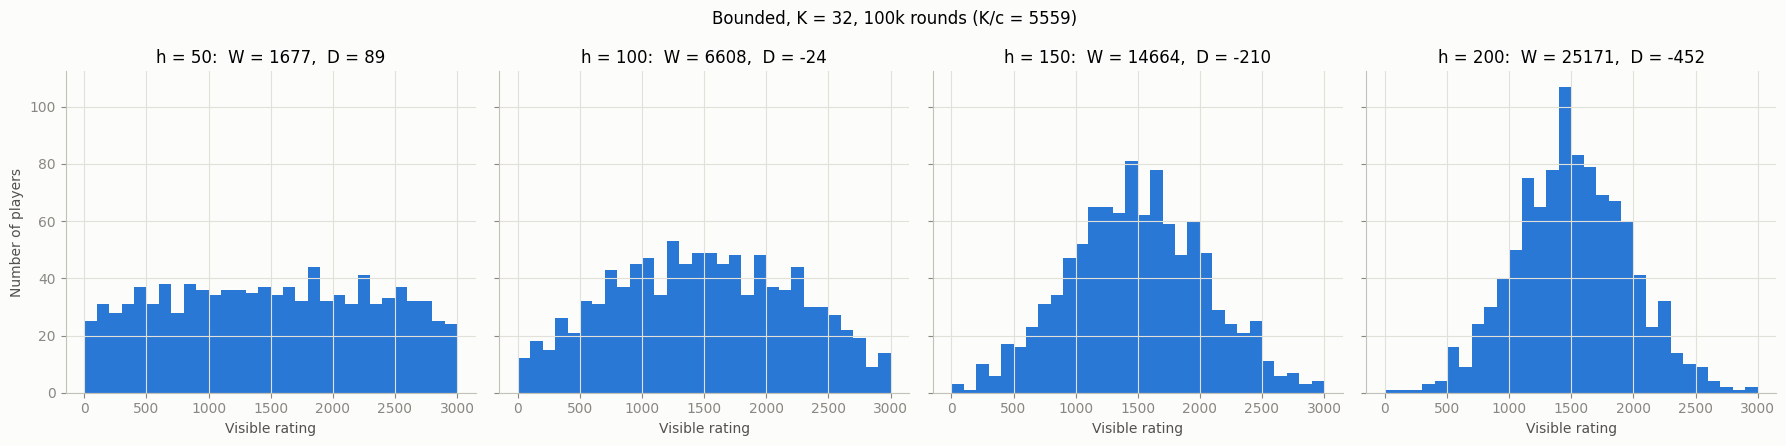

h =  50: KS distance to uniform = 0.023, SD = 830 (uniform: 866), stretch = 2.36
h = 100: KS distance to uniform = 0.084, SD = 717 (uniform: 866), stretch = 2.06
h = 150: KS distance to uniform = 0.174, SD = 544 (uniform: 866), stretch = 1.58
h = 200: KS distance to uniform = 0.214, SD = 457 (uniform: 866), stretch = 1.32



N =  20: lowest rating    302, highest   2867  (neighbour gap at uniform density L/N = 150)


N =  50: lowest rating     32, highest   2936  (neighbour gap at uniform density L/N = 60)


N = 200: lowest rating      6, highest   3000  (neighbour gap at uniform density L/N = 15)


In [18]:
# Conditions: the window must satisfy W < K/c (D > 0), and the pool must be large enough to reach both walls
hs_J5 = [50, 100, 150, 200]
J5 = simulate(32, hs_J5, 1000, 100000, true_ratings=th_J4, bounded=(0, L), log_every=10000, seed=48)

fig, axs = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for j, ax in enumerate(axs):
    W_j = J5["matched_dr2"][-3:, j].mean()
    ax.hist(J5["ratings"][j], bins=30, range=(0, L), color=BLUE)
    ax.set_title(f"h = {hs_J5[j]}:  W = {W_j:.0f},  D = {effective_diffusion(32, W_j):.0f}")
    ax.set_xlabel("Visible rating")
axs[0].set_ylabel("Number of players")
plt.suptitle(f"Bounded, K = 32, 100k rounds (K/c = {critical_gap2(32):.0f})")
plt.tight_layout()
plt.show()

for j, h_j in enumerate(hs_J5):
    r = J5["ratings"][j]
    print(f"h = {h_j:>3}: KS distance to uniform = {kstest(r / L, 'uniform').statistic:.3f}, SD = {r.std():.0f} "
          f"(uniform: {L / np.sqrt(12):.0f}), stretch = {stretch(r, th_J4):.2f}")
print()
for N in [20, 50, 200]:
    r = simulate(32, 50, N, 100000, bounded=(0, L), log_every=10000, seed=49 + N)["ratings"][0]
    print(f"N = {N:>3}: lowest rating {r.min():6.0f}, highest {r.max():6.0f}  (neighbour gap at uniform density L/N = {L / N:.0f})")